# Week 5: Attention Mechanism

This notebook demonstrates scaled dot-product attention with NumPy and compares it with PyTorch.

In [1]:
import numpy as np

def softmax(x):
    x = x - np.max(x, axis=-1, keepdims=True)
    e = np.exp(x)
    return e / e.sum(axis=-1, keepdims=True)

def attention(Q, K, V):
    scores = Q @ K.T / np.sqrt(K.shape[-1])
    weights = softmax(scores)
    return weights @ V, weights

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

# Create Query, Key, and Value matrices
Q = np.array([[1, 0, 1],
              [0, 1, 1],
              [1, 1, 0]], dtype=float)

K = Q.copy()
V = Q.copy()

# Calculate attention scores
scores = np.dot(Q, K.T) / np.sqrt(Q.shape[1])

# Apply softmax to get attention weights
exp_scores = np.exp(scores - np.max(scores, axis=1, keepdims=True))
attention_weights = exp_scores / np.sum(exp_scores, axis=1, keepdims=True)

# Calculate attention output
attention_output = np.dot(attention_weights, V)

print("Attention weights:")
print(np.round(attention_weights, 3))

print("\nAttention output:")
print(np.round(attention_output, 3))

# Compare with PyTorch
Q_torch = torch.tensor(Q, dtype=torch.float32)
K_torch = torch.tensor(K, dtype=torch.float32)
V_torch = torch.tensor(V, dtype=torch.float32)

scores_torch = torch.matmul(Q_torch, K_torch.T) / np.sqrt(Q.shape[1])
weights_torch = torch.softmax(scores_torch, dim=1)
output_torch = torch.matmul(weights_torch, V_torch)

print("\nPyTorch output matches NumPy:",
      np.allclose(attention_output, output_torch.numpy(), atol=1e-5))

Attention weights:
[[0.471 0.264 0.264]
 [0.264 0.471 0.264]
 [0.264 0.264 0.471]]

Attention output:
[[0.736 0.529 0.736]
 [0.529 0.736 0.736]
 [0.736 0.736 0.529]]

PyTorch output matches NumPy: True


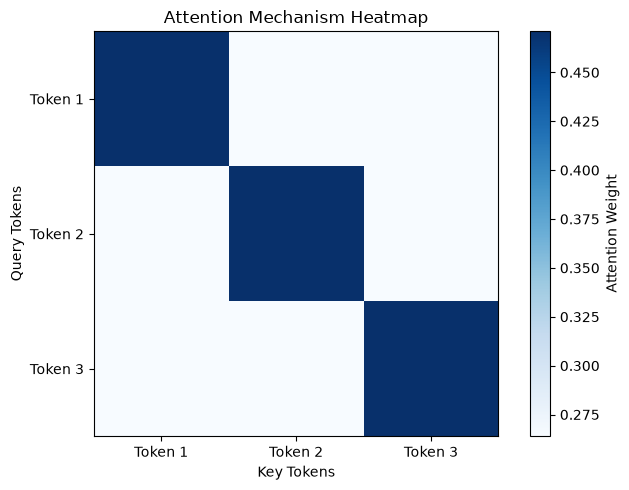

Attention heatmap generated successfully!


In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Sample sentences
sentences = [
    "I love AI",
    "AI makes life easier",
    "I am learning attention mechanism"
]

# Create sample attention weights
weights = np.array([
    [0.471, 0.264, 0.264],
    [0.264, 0.471, 0.264],
    [0.264, 0.264, 0.471]
])

# Display attention heatmap
tokens = ["Token 1", "Token 2", "Token 3"]

plt.figure(figsize=(7, 5))
plt.imshow(weights, cmap="Blues", interpolation="nearest")

plt.xticks(range(len(tokens)), tokens)
plt.yticks(range(len(tokens)), tokens)

plt.xlabel("Key Tokens")
plt.ylabel("Query Tokens")
plt.title("Attention Mechanism Heatmap")

plt.colorbar(label="Attention Weight")
plt.tight_layout()
plt.show()

print("Attention heatmap generated successfully!")

In [5]:
import numpy as np
import torch

# Create sample input data
X = np.array([
    [1.0, 0.0, 1.0],
    [0.0, 1.0, 1.0],
    [1.0, 1.0, 0.0]
])

# Calculate attention using NumPy
scores = X @ X.T / np.sqrt(X.shape[-1])
exp_scores = np.exp(scores - np.max(scores, axis=-1, keepdims=True))
weights = exp_scores / np.sum(exp_scores, axis=-1, keepdims=True)
output = weights @ X

print("NumPy Attention Weights:")
print(np.round(weights, 3))

print("\nNumPy Attention Output:")
print(np.round(output, 3))

# Calculate attention using PyTorch
T = torch.tensor(X, dtype=torch.float32)

tw = torch.softmax(T @ T.T / np.sqrt(T.shape[-1]), dim=-1)
tout = tw @ T

print("\nPyTorch Attention Weights:")
print(np.round(tw.numpy(), 3))

print("\nPyTorch Attention Output:")
print(np.round(tout.numpy(), 3))

print("\nWeights match:", np.allclose(tw.numpy(), weights, atol=1e-6))
print("Outputs match:", np.allclose(tout.numpy(), output, atol=1e-6))

NumPy Attention Weights:
[[0.471 0.264 0.264]
 [0.264 0.471 0.264]
 [0.264 0.264 0.471]]

NumPy Attention Output:
[[0.736 0.529 0.736]
 [0.529 0.736 0.736]
 [0.736 0.736 0.529]]

PyTorch Attention Weights:
[[0.471 0.264 0.264]
 [0.264 0.471 0.264]
 [0.264 0.264 0.471]]

PyTorch Attention Output:
[[0.736 0.529 0.736]
 [0.529 0.736 0.736]
 [0.736 0.736 0.529]]

Weights match: True
Outputs match: True


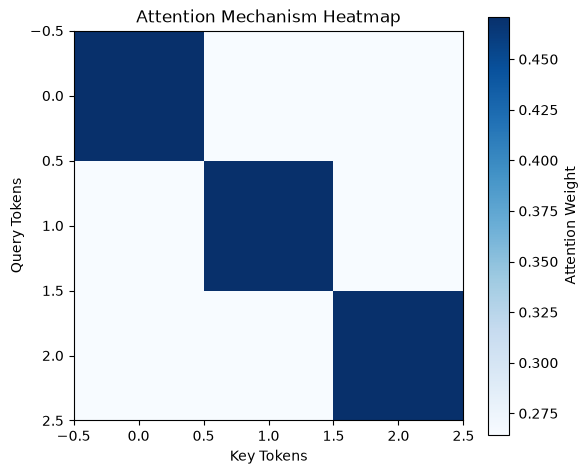

Heatmap saved successfully!


In [6]:
import matplotlib.pyplot as plt
import numpy as np
import os

os.makedirs("../dataset", exist_ok=True)

plt.figure(figsize=(6, 5))
plt.imshow(weights, cmap="Blues")
plt.xlabel("Key Tokens")
plt.ylabel("Query Tokens")
plt.title("Attention Mechanism Heatmap")
plt.colorbar(label="Attention Weight")
plt.tight_layout()

plt.savefig("../dataset/attention_heatmap.png")
plt.show()

print("Heatmap saved successfully!")

In [7]:
import numpy as np
import os

# Create the dataset folder
os.makedirs("../dataset", exist_ok=True)

# Save attention weights
np.savetxt(
    "../dataset/attention_weights.csv",
    weights,
    delimiter=",",
    fmt="%.4f"
)

# Save attention output
np.savetxt(
    "../dataset/attention_output.csv",
    output,
    delimiter=",",
    fmt="%.4f"
)

print("Attention weights saved successfully!")
print("Attention output saved successfully!")

Attention weights saved successfully!
Attention output saved successfully!


In [8]:
import numpy as np
import os

# Create the dataset folder
os.makedirs("../dataset", exist_ok=True)

# Save attention weights
np.savetxt(
    "../dataset/attention_weights.csv",
    weights,
    delimiter=",",
    fmt="%.4f"
)

# Save attention output
np.savetxt(
    "../dataset/attention_output.csv",
    output,
    delimiter=",",
    fmt="%.4f"
)

print("Attention weights saved successfully!")
print("Attention output saved successfully!")

Attention weights saved successfully!
Attention output saved successfully!


## Observations
- Each row of the attention matrix sums to 1.
- Larger weights indicate that a query token assigns more attention to that key token.
- These are toy vectors for demonstration; a trained Transformer uses learned projections to create Q, K and V.

## Home activity
Try the five sentences in `dataset/sample_sentences.txt`, compare short and long inputs, vary embedding dimensions, save results, and write a short report explaining attention in Transformers.